# D07 · Два изображения: геометрия соответствий и две роли SVD

Численный спутник **слайда 7** из `lecture02_final_v2_applications.qmd`.

**Результат:** создадим две перспективные камеры, спроецируем общие 3D-точки, добавим шум в пикселях и оценим фундаментальную матрицу $F$. Первая SVD решает однородную линейную задачу, вторая задаёт ранг 2. Затем проверим эпиполярные ограничения и нарисуем линии на обеих плоскостях изображения.

Все данные **синтетические**, создаются локально; интернет и GPU для запуска не нужны. Известные камеры используются только для генерации и независимой проверки. Алгоритм получает только пары 2D-координат. Это демонстрация геометрии соответствий, без обнаружения признаков, сопоставления фотографий и метрического восстановления сцены.

Запуск: выберите Python-ядро с `numpy`, `pandas`, `matplotlib`, `ipython` и выполните **Restart Kernel → Run All**. Ожидаемое время — несколько секунд на CPU. `SEED` и уровень шума можно менять в следующей ячейке.

In [1]:
import sys
import platform
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
N_FIT = 64
N_TEST = 240
NOISE_PX = 1.0
WIDTH, HEIGHT = 1280, 960
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.grid": True})

display(pd.DataFrame({
    "параметр": ["seed", "Python", "NumPy", "pandas", "Matplotlib", "оборудование", "ОС"],
    "значение": [SEED, sys.version.split()[0], version("numpy"), version("pandas"),
                 version("matplotlib"), platform.machine() + " / CPU", platform.platform()],
}))

,параметр,значение
0,seed,42
1,Python,3.12.14
2,NumPy,2.5.3
3,pandas,3.0.6
4,Matplotlib,3.11.2
5,оборудование,arm64 / CPU
6,ОС,macOS-26.6.2-arm64-arm-64bit


## 1. Две камеры и одна сцена

Для первой камеры $P_1=K_1[I\mid0]$, для второй $P_2=K_2[R\mid t]$. Здесь $R,t$ переводят мировую точку из системы первой камеры в систему второй; центр второй камеры в мировых координатах равен $-R^\top t$.

Для точки $X$ вычисляем $\widetilde x=P[X^\top,1]^\top$, затем делим первые две координаты на третью. Случайные глубины исключают специально плоскую сцену. Все точки перед обеими камерами. Отдельные тестовые точки нужны для оценки переноса найденной геометрии на новые соответствия.

In [2]:
def skew(v):
    x, y, z = np.asarray(v, dtype=float)
    return np.array([[0, -z, y], [z, 0, -x], [-y, x, 0]])


def homogeneous(points):
    points = np.asarray(points, dtype=float)
    return np.column_stack([points, np.ones(len(points))])


def project(points_3d, K, R, t):
    camera_points = points_3d @ R.T + t
    if np.any(camera_points[:, 2] <= 0):
        raise ValueError("Есть точки позади камеры")
    pixels_h = camera_points @ K.T
    return pixels_h[:, :2] / pixels_h[:, 2:3]


angle = np.deg2rad(7.0)
R = np.array([[np.cos(angle), 0, np.sin(angle)],
              [0, 1, 0],
              [-np.sin(angle), 0, np.cos(angle)]])
t = np.array([-0.85, 0.06, 0.03])
K1 = np.array([[1040., 0., WIDTH / 2], [0., 1040., HEIGHT / 2], [0., 0., 1.]])
K2 = np.array([[1100., 0., WIDTH / 2 + 24], [0., 1060., HEIGHT / 2 - 12], [0., 0., 1.]])
points_3d = rng.uniform([-1.7, -1.2, 4.0], [1.7, 1.2, 9.5], size=(N_FIT + N_TEST, 3))
x1_clean_all = project(points_3d, K1, np.eye(3), np.zeros(3))
x2_clean_all = project(points_3d, K2, R, t)
x1_clean, x2_clean = x1_clean_all[:N_FIT], x2_clean_all[:N_FIT]
x1_test, x2_test = x1_clean_all[N_FIT:], x2_clean_all[N_FIT:]
x1 = x1_clean + rng.normal(0, NOISE_PX, x1_clean.shape)
x2 = x2_clean + rng.normal(0, NOISE_PX, x2_clean.shape)
x1_test_noisy = x1_test + rng.normal(0, NOISE_PX, x1_test.shape)
x2_test_noisy = x2_test + rng.normal(0, NOISE_PX, x2_test.shape)

# F известна с точностью до ненулевого множителя.
F_true = np.linalg.inv(K2).T @ skew(t) @ R @ np.linalg.inv(K1)
F_true /= np.linalg.norm(F_true)
assert np.linalg.matrix_rank(points_3d - points_3d.mean(axis=0)) == 3
for pixels in (x1_clean_all, x2_clean_all):
    assert np.all((pixels[:, 0] > 0) & (pixels[:, 0] < WIDTH))
    assert np.all((pixels[:, 1] > 0) & (pixels[:, 1] < HEIGHT))

matches = pd.DataFrame(np.column_stack([x1[:8], x2[:8]]),
                       columns=["u1, px", "v1, px", "u2, px", "v2, px"],
                       index=np.arange(1, 9))
matches.index.name = "ID точки"
display(matches.round(2))
print(f"Подгонка: {N_FIT} пар; независимая проверка: {N_TEST} пар; шум σ={NOISE_PX:g} px")

,"u1, px","v1, px","u2, px","v2, px"
ID точки,,,,
1,751.29,463.46,810.69,457.66
2,713.40,370.68,776.70,364.64
3,835.18,632.06,808.35,638.70
4,621.96,444.12,674.01,437.78
5,716.51,603.41,736.71,606.81
6,417.50,510.76,357.89,514.00
7,781.40,520.27,836.33,518.12
8,581.97,612.88,633.04,609.74


Подгонка: 64 пар; независимая проверка: 240 пар; шум σ=1 px


## 2. Первая SVD: найти направление решения

Для однородных $x=(u,v,1)^\top$ и $x'=(u',v',1)^\top$ имеем $x'^\top F x=0$. При построчном разворачивании $F$ в вектор строка матрицы ограничений имеет вид

$$A_i=[u'u,\ u'v,\ u',\ v'u,\ v'v,\ v',\ u,\ v,\ 1].$$

Нужен единичный вектор $f$, минимизирующий $\|Af\|_2$. Он берётся из последней строки $V^\top$.

**Важная деталь для ровно восьми пар:** у $A$ размер $8\times9$. `full_matrices=False` вернёт только восемь строк $V^\top$ и потеряет нужное одномерное ядро. Здесь используется `full_matrices=True`. Размеры результата описаны в [документации NumPy](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html).

## 3. Нормализация и вторая SVD

Нормализация Хартли отдельно для каждого изображения переносит центр точек в ноль и делает среднее расстояние до него равным $\sqrt2$. После решения в этих координатах заменяем последнее сингулярное значение $\widehat F$ нулём. Возвращаемся к пикселям: $F=T_2^\top\widehat F T_1$.

Первая SVD ищет параметры по соответствиям; вторая проецирует матрицу на ограничение ранга. Нормализация улучшает масштаб системы и меняет алгебраическую задачу с шумом. Она не делает оценивание устойчивым к неверным соответствиям. Метод и его мотивация изложены в [работе Хартли, авторская версия](https://users.cecs.anu.edu.au/~hartley/Papers/fundamental/electronic-submission/fundamental.pdf).

In [3]:
def validate_matches(p1, p2):
    p1, p2 = np.asarray(p1, dtype=float), np.asarray(p2, dtype=float)
    if p1.ndim != 2 or p1.shape[1] != 2 or p1.shape != p2.shape or len(p1) < 8:
        raise ValueError("Нужны две конечные матрицы одинаковой формы (N, 2), N >= 8")
    if not np.all(np.isfinite(p1)) or not np.all(np.isfinite(p2)):
        raise ValueError("Координаты должны быть конечными")
    for p in (p1, p2):
        spread = np.linalg.svd(p - p.mean(axis=0), compute_uv=False)
        if spread[0] <= np.finfo(float).eps or spread[1] <= 1e-10 * spread[0]:
            raise ValueError("Совпадающие или почти коллинеарные точки: вырожденная конфигурация")
    return p1, p2


def hartley_normalize(points):
    center = points.mean(axis=0)
    centered = points - center
    mean_distance = np.linalg.norm(centered, axis=1).mean()
    if mean_distance <= np.finfo(float).eps:
        raise ValueError("Недостаточный разброс точек")
    scale = np.sqrt(2) / mean_distance
    T = np.array([[scale, 0, -scale * center[0]],
                  [0, scale, -scale * center[1]], [0, 0, 1.]])
    return centered * scale, T


def design_matrix(p1, p2):
    u, v = p1.T
    up, vp = p2.T
    return np.column_stack([up*u, up*v, up, vp*u, vp*v, vp, u, v, np.ones(len(p1))])


def unit_fundamental(F):
    F = np.asarray(F, dtype=float)
    if F.shape != (3, 3) or not np.all(np.isfinite(F)) or np.linalg.norm(F) == 0:
        raise ValueError("Нужна ненулевая конечная матрица 3 × 3")
    return F / np.linalg.norm(F)


def estimate_fundamental(p1, p2, normalize=True):
    p1, p2 = validate_matches(p1, p2)
    # Проверяем неоднозначность в нормализованных координатах даже для raw-ветки.
    q1, T1 = hartley_normalize(p1)
    q2, T2 = hartley_normalize(p2)
    if np.linalg.matrix_rank(design_matrix(q1, q2)) < 8:
        raise ValueError("Матрица ограничений имеет ранг < 8: решение неоднозначно")
    if not normalize:
        q1, q2, T1, T2 = p1, p2, np.eye(3), np.eye(3)
    A = design_matrix(q1, q2)
    _, singular_A, Vt = np.linalg.svd(A, full_matrices=True)
    f = Vt[-1]  # Для A=(8,9) это именно 9-я строка Vt.
    F_before = f.reshape(3, 3)
    U, singular_F, Vt_F = np.linalg.svd(F_before)
    if singular_F[1] <= 1e-12 * singular_F[0]:
        raise ValueError("Оценка фундаментальной матрицы имеет ранг < 2")
    singular_rank2 = singular_F.copy()
    singular_rank2[-1] = 0.0
    F_after = (U * singular_rank2) @ Vt_F
    F = unit_fundamental(T2.T @ F_after @ T1)
    diagnostics = dict(A=A, f=f, singular_A=singular_A, Vt_shape=Vt.shape,
                       F_before=F_before, F_after=F_after,
                       singular_F=singular_F, T1=T1, T2=T2)
    return F, diagnostics


F_normalized, info_normalized = estimate_fundamental(x1, x2, normalize=True)
F_raw, info_raw = estimate_fundamental(x1, x2, normalize=False)
print("F (норма Фробениуса = 1):\n", F_normalized)
print("SVD матрицы ограничений:", info_normalized["A"].shape,
      "→ Vt", info_normalized["Vt_shape"])
print("Сингулярные значения F после возврата к пикселям:",
      np.linalg.svd(F_normalized, compute_uv=False))

F (норма Фробениуса = 1):
 [[ 0.       0.      -0.00308]
 [ 0.       0.      -0.03732]
 [ 0.00117  0.03442  0.9987 ]]
SVD матрицы ограничений: (64, 9) → Vt (9, 9)
Сингулярные значения F после возврата к пикселям: [1.      0.00129 0.     ]


## 4. Проверки на данных без шума

$F$ и $cF$ описывают одинаковые ограничения. Поэтому сравниваем матрицы после нормировки, выбирая лучший знак; не сравниваем отдельные элементы без учёта масштаба. Проверяем как все пары, так и **ровно восемь**.

Эти проверки проверяют реализацию в известной синтетической сцене. Они не доказывают качество на фотографиях. При шуме почти вырожденная конфигурация может пройти проверку ранга; совпадающие точки, прямая, плоская сцена и чистое вращение требуют отдельного внимания.

In [4]:
def epipolar_residuals(F, p1, p2):
    return np.einsum("ni,ni->n", homogeneous(p2), homogeneous(p1) @ F.T)


def scale_sign_distance(F, G):
    F, G = unit_fundamental(F), unit_fundamental(G)
    return min(np.linalg.norm(F - G), np.linalg.norm(F + G))


F_clean, info_clean = estimate_fundamental(x1_clean, x2_clean)
F_eight, info_eight = estimate_fundamental(x1_clean[:8], x2_clean[:8])
assert F_clean.shape == F_eight.shape == (3, 3)
assert info_eight["Vt_shape"] == (9, 9)
assert np.linalg.norm(info_eight["A"] @ info_eight["f"]) < 1e-10
assert scale_sign_distance(F_clean, F_true) < 1e-8
assert scale_sign_distance(F_eight, F_true) < 1e-8
assert scale_sign_distance(-7 * F_clean, F_true) < 1e-8
assert np.max(np.abs(epipolar_residuals(F_clean, x1_clean, x2_clean))) < 1e-8
assert np.linalg.matrix_rank(F_normalized, tol=1e-10) == 2
assert np.linalg.svd(F_normalized, compute_uv=False)[-1] < 1e-12

# Показываем, почему reduced SVD здесь неверна: нужного вектора в её Vt нет.
_, _, Vt_reduced = np.linalg.svd(info_eight["A"], full_matrices=False)
assert Vt_reduced.shape == (8, 9)
print("Ровно 8 пар:")
print("  ||A @ f||, полная SVD :", np.linalg.norm(info_eight["A"] @ info_eight["f"]))
print("  ||A @ Vt[-1]||, reduced:", np.linalg.norm(info_eight["A"] @ Vt_reduced[-1]))

# Явные вырождения должны давать понятную ошибку, а не произвольную F.
line = np.column_stack([np.arange(8), 2 * np.arange(8) + 1])
plane3d = points_3d[:12].copy()
plane3d[:, 2] = 6.0
plane1 = project(plane3d, K1, np.eye(3), np.zeros(3))
plane2 = project(plane3d, K2, R, t)
bad_inputs = [(np.ones((8, 2)), np.ones((8, 2))), (line, line),
              (x1_clean[:7], x2_clean[:7]), (plane1, plane2),
              (np.full((8, 2), np.nan), x2_clean[:8])]
for bad1, bad2 in bad_inputs:
    try:
        estimate_fundamental(bad1, bad2)
    except ValueError:
        pass
    else:
        raise AssertionError("Вырожденные/некорректные данные не были отклонены")
print("Проверки формы, масштаба, ранга, эпиполярного ограничения и вырождений пройдены.")

Ровно 8 пар:
  ||A @ f||, полная SVD : 5.257593145633281e-16
  ||A @ Vt[-1]||, reduced: 0.09555368153460905
Проверки формы, масштаба, ранга, эпиполярного ограничения и вырождений пройдены.


## 5. Что меняет нормализация

Слева — относительные сингулярные значения матрицы $A$. Сравниваем также $\sigma_1(A)/\sigma_8(A)$: девятое направление в точной задаче должно быть ядром, поэтому полное число обусловленности точной системы бесконечно и само по себе малоинформативно.

Справа — спектр матрицы $\widehat F$ **в нормализованных координатах**, до и после второго шага SVD. Принудительное зануление последнего значения задаёт ограничение ранга 2. Это ближайшая матрица по норме Фробениуса в этих координатах, а не решение задачи минимизации пиксельной ошибки.

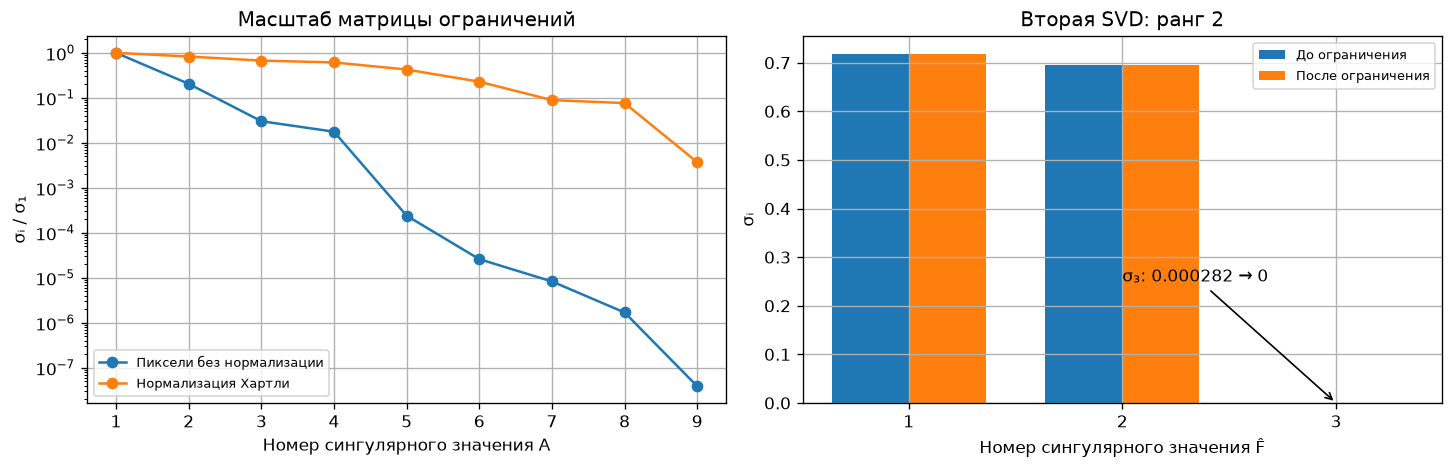

,метод,σ₁(A) / σ₈(A),σ₃(F̂) до ограничения
0,Без нормализации,589515.906956,7.327124e-07
1,Нормализация Хартли,13.057250,2.823951e-04


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
for name, info in [("Пиксели без нормализации", info_raw), ("Нормализация Хартли", info_normalized)]:
    singular = info["singular_A"]
    axes[0].semilogy(np.arange(1, len(singular) + 1), singular / singular[0], "o-", label=name)
axes[0].set(xlabel="Номер сингулярного значения A", ylabel="σᵢ / σ₁",
            title="Масштаб матрицы ограничений")
axes[0].legend(fontsize=8)
values_before = info_normalized["singular_F"]
values_after = np.linalg.svd(info_normalized["F_after"], compute_uv=False)
locations = np.arange(1, 4)
axes[1].bar(locations - 0.18, values_before, width=0.36, label="До ограничения")
axes[1].bar(locations + 0.18, values_after, width=0.36, label="После ограничения")
axes[1].set(xticks=locations, xlabel="Номер сингулярного значения F̂", ylabel="σᵢ",
            title="Вторая SVD: ранг 2")
axes[1].annotate(f"σ₃: {values_before[-1]:.3g} → 0", xy=(3, 0), xytext=(2.0, 0.25),
                 arrowprops={"arrowstyle": "->"})
axes[1].legend(fontsize=8)
plt.show()

display(pd.DataFrame([
    {"метод": name,
     "σ₁(A) / σ₈(A)": info["singular_A"][0] / info["singular_A"][7],
     "σ₃(F̂) до ограничения": info["singular_F"][-1]}
    for name, info in [("Без нормализации", info_raw), ("Нормализация Хартли", info_normalized)]
]))

## 6. Ошибка в пикселях: расстояние Сэмпсона

Алгебраический остаток $r_i=x_i'^\top F x_i$ зависит от масштаба $F$, поэтому сам по себе не является пиксельной ошибкой. Используем

$$d_{S,i}^2=\frac{r_i^2}{(Fx_i)_1^2+(Fx_i)_2^2+(F^\top x_i')_1^2+(F^\top x_i')_2^2}.$$

Это приближение первого порядка к суммарной квадратичной коррекции двух наблюдений. В таблице приведён $\sqrt{\operatorname{mean}(d_S^2)}$ в пикселях. Это **не ошибка восстановления 3D** и не точная reprojection error.

Тест без шума показывает отклонение оценённой геометрии от истинной на новых точках; тест с шумом включает и шум новых измерений. Даже истинная $F$ даст ненулевую ошибку на зашумлённых парах. Нормализация полезна, но её превосходство на каждом случайном наборе не гарантируется.

,"fit, шум / px","test, без шума / px","test, шум / px"
матрица,,,
Истинная F,1.08681,0.00000,1.08393
Без нормализации,23.29147,24.04284,24.00845
Нормализация Хартли,1.02672,0.47238,1.18572


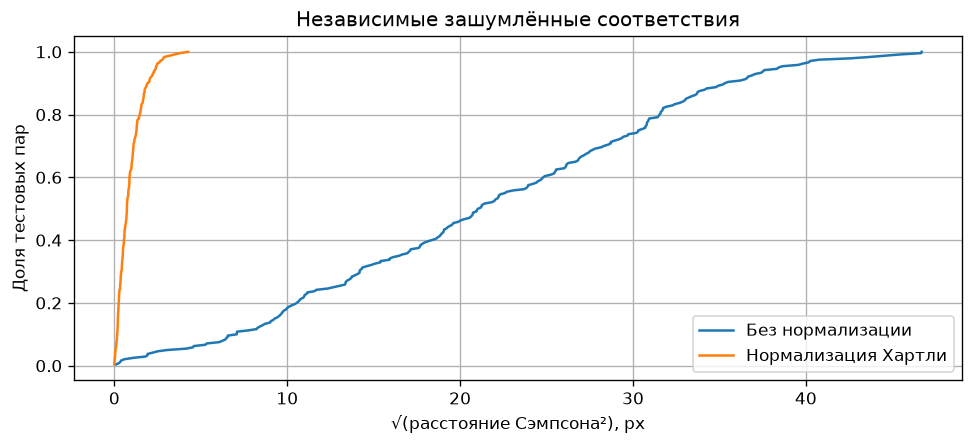

In [6]:
def sampson_squared(F, p1, p2):
    # Нормировка F сохраняет геометрию и делает абсолютный численный порог осмысленным.
    F = unit_fundamental(F)
    p1h, p2h = homogeneous(p1), homogeneous(p2)
    Fp1, Ft_p2 = p1h @ F.T, p2h @ F
    numerator = np.sum(p2h * Fp1, axis=1) ** 2
    denominator = np.sum(Fp1[:, :2]**2 + Ft_p2[:, :2]**2, axis=1)
    # Вблизи обоих эпиполей линейное приближение не определено.
    # Не превращаем 0/0 в хорошее нулевое расстояние: оставляем NaN.
    valid = denominator > 100 * np.finfo(float).tiny
    result = np.full(len(p1), np.nan)
    np.divide(numerator, denominator, out=result, where=valid)
    return result


def sampson_rms(F, p1, p2):
    distances = sampson_squared(F, p1, p2)
    if not np.all(np.isfinite(distances)):
        raise ValueError("Сэмпсон не определён для некоторых пар (проверьте эпиполи)")
    return np.sqrt(distances.mean())


rows = []
models = {"Истинная F": F_true, "Без нормализации": F_raw, "Нормализация Хартли": F_normalized}
for name, F in models.items():
    rows.append({"матрица": name,
                 "fit, шум / px": sampson_rms(F, x1, x2),
                 "test, без шума / px": sampson_rms(F, x1_test, x2_test),
                 "test, шум / px": sampson_rms(F, x1_test_noisy, x2_test_noisy)})
metrics = pd.DataFrame(rows).set_index("матрица")
display(metrics.round(5))
assert sampson_rms(F_true, x1_test, x2_test) < 1e-8
assert np.allclose(sampson_squared(-5 * F_normalized, x1, x2),
                   sampson_squared(F_normalized, x1, x2))

fig, ax = plt.subplots(figsize=(8, 3.6), constrained_layout=True)
for name, F in [("Без нормализации", F_raw), ("Нормализация Хартли", F_normalized)]:
    errors = np.sort(np.sqrt(sampson_squared(F, x1_test_noisy, x2_test_noisy)))
    ax.plot(errors, np.arange(1, len(errors) + 1) / len(errors), label=name)
ax.set(xlabel="√(расстояние Сэмпсона²), px", ylabel="Доля тестовых пар",
       title="Независимые зашумлённые соответствия")
ax.legend()
plt.show()

## 7. Увидеть эпиполярное ограничение

На обеих картинках цвет и ID обозначают **одну и ту же точку сцены**. Выделена пара 8. Для неё строим $l'=Fx$ на втором изображении и $l=F^\top x'$ на первом. При шуме наблюдение не обязано лежать точно на оценённой прямой. Пунктир — ограничение истинной геометрии, тоже построенное от зашумлённой точки в другом кадре.

Фон — пустая плоскость изображения, а не фотография. Линии обрезаются по рамке; расчёт учитывает также вертикальные и горизонтальные линии.

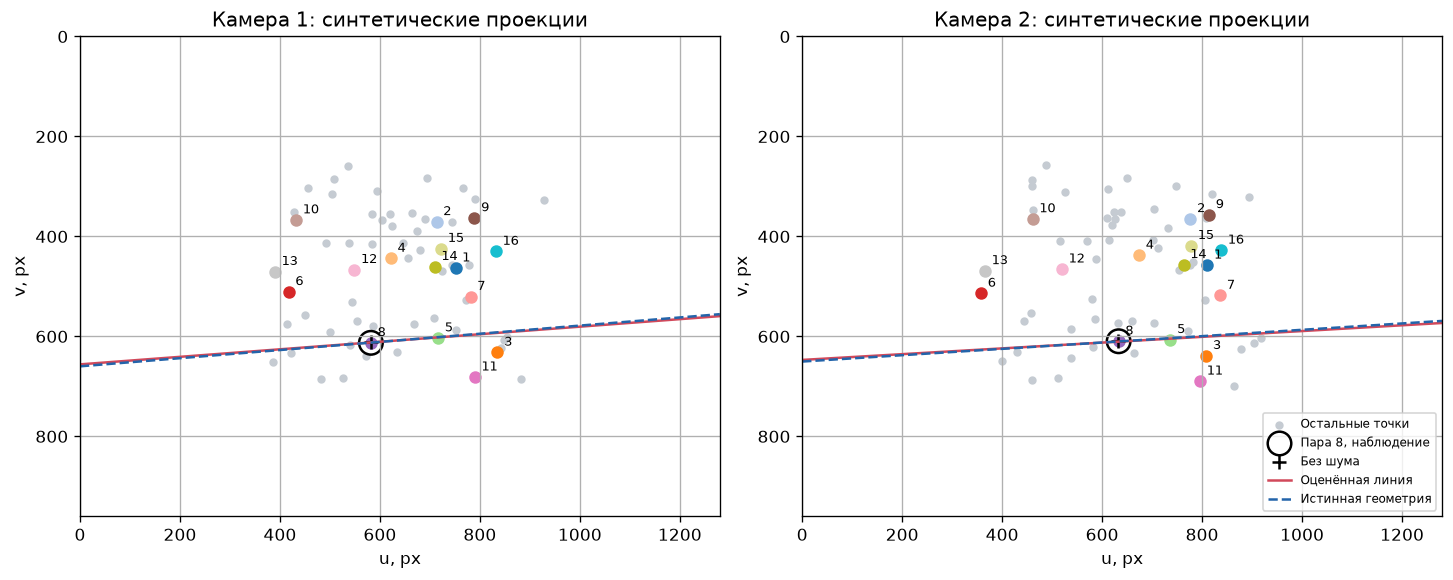

In [7]:
def line_segment_in_image(line, width, height):
    a, b, c = np.asarray(line, dtype=float)
    norm = np.hypot(a, b)
    if norm <= np.finfo(float).tiny:
        return None
    a, b, c = a / norm, b / norm, c / norm
    candidates = []
    if abs(b) > 1e-12:
        for u in (0., float(width)):
            v = -(a * u + c) / b
            if -1e-8 <= v <= height + 1e-8:
                candidates.append(np.array([u, np.clip(v, 0, height)]))
    if abs(a) > 1e-12:
        for v in (0., float(height)):
            u = -(b * v + c) / a
            if -1e-8 <= u <= width + 1e-8:
                candidates.append(np.array([np.clip(u, 0, width), v]))
    unique = []
    for candidate in candidates:
        if not any(np.linalg.norm(candidate - old) < 1e-7 for old in unique):
            unique.append(candidate)
    if len(unique) < 2:
        return None
    # При попадании в угол выбираем самые удалённые пересечения.
    return max(((p, q) for i, p in enumerate(unique) for q in unique[i+1:]),
               key=lambda pair: np.linalg.norm(pair[0] - pair[1]))


assert line_segment_in_image([1, 0, -10], WIDTH, HEIGHT) is not None
assert line_segment_in_image([0, 1, -20], WIDTH, HEIGHT) is not None
assert line_segment_in_image([1, 0, WIDTH], WIDTH, HEIGHT) is None

selected = 7
colors = plt.cm.tab20(np.arange(min(16, N_FIT)) / max(1, min(16, N_FIT)))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7), constrained_layout=True)
for camera_id, (ax, observed, clean) in enumerate(zip(axes, [x1, x2], [x1_clean, x2_clean]), start=1):
    ax.scatter(observed[:, 0], observed[:, 1], c="#c5cbd2", s=16, label="Остальные точки")
    for i in range(min(16, N_FIT)):
        ax.scatter(*observed[i], s=42, color=colors[i])
        ax.annotate(str(i+1), observed[i], xytext=(4, 4), textcoords="offset points", fontsize=8)
    ax.scatter(*observed[selected], s=200, facecolor="none", edgecolor="black", lw=1.5,
               label="Пара 8, наблюдение")
    ax.scatter(*clean[selected], marker="+", color="black", s=80, label="Без шума")
    for model, linestyle, color, label in [(F_normalized, "-", "#d1495b", "Оценённая линия"),
                                           (F_true, "--", "#2364aa", "Истинная геометрия")]:
        line = (model.T @ homogeneous(x2[[selected]])[0] if camera_id == 1
                else model @ homogeneous(x1[[selected]])[0])
        segment = line_segment_in_image(line, WIDTH, HEIGHT)
        if segment is not None:
            segment = np.array(segment)
            ax.plot(segment[:, 0], segment[:, 1], linestyle, color=color, lw=1.5, label=label)
    ax.set(xlim=(0, WIDTH), ylim=(HEIGHT, 0), aspect="equal", xlabel="u, px", ylabel="v, px",
           title=f"Камера {camera_id}: синтетические проекции")
axes[1].legend(fontsize=7, loc="lower right")
plt.show()

## 8. Неверные соответствия: отдельная проблема

Переставим вторые точки у четверти обучающих пар. Это имитирует ошибки сопоставления. Сравним модели на **той же чистой тестовой геометрии**. У обычного eight-point все строки участвуют в одной задаче; один большой остаток может изменить решение. Нормализация не заменяет проверку соответствий и робастную оценку.

In [8]:
outlier_rng = np.random.default_rng(SEED + 1)
corrupted_x2 = x2.copy()
outlier_ids = outlier_rng.choice(N_FIT, N_FIT // 4, replace=False)
corrupted_x2[outlier_ids] = x2[np.roll(outlier_ids, 1)]
F_outliers, _ = estimate_fundamental(x1, corrupted_x2)
display(pd.DataFrame({
    "обучающие соответствия": ["Правильные, с шумом", "25% неправильных, с шумом"],
    "Sampson RMS на чистом test, px": [sampson_rms(F_normalized, x1_test, x2_test),
                                       sampson_rms(F_outliers, x1_test, x2_test)]
}))
print("Число намеренно испорченных пар:", len(outlier_ids))

,обучающие соответствия,"Sampson RMS на чистом test, px"
0,"Правильные, с шумом",0.472381
1,"25% неправильных, с шумом",29.463085


Число намеренно испорченных пар: 16


## Что попробовать самостоятельно

1. Измените `NOISE_PX` с 1 на 0, 0.5 и 3. Сравните обучение и независимые соответствия. Не делайте вывод по одному seed.
2. Поставьте `N_FIT = 8`: тесты останутся корректными, но оценка с шумом станет менее устойчивой.
3. Сблизьте камеры, уменьшив длину `t`. Сравните расстояния Сэмпсона и близость матрицы к истине. Малый остаток не гарантирует устойчивой 3D-реконструкции.
4. Зафиксируйте всем точкам одинаковую глубину. Для точных данных код отклоняет неоднозначную систему; добавленный шум может скрыть вырождение численного ранга.
5. Попробуйте робастное оценивание поверх этих функций: выбирать подмножества, проверять согласие по расстоянию Сэмпсона, затем переоценивать $F$ на согласованных парах. Корректный выбор порога и числа попыток — самостоятельная часть задачи.

**Итог наблюдений:** оценивание $F$ использует две разные SVD; корректная форма разложения важна для восьми пар. Геометрия связывает соответствующие пиксели эпиполярными линиями. Синтетическая сцена позволяет проверять код по известной истине; для фотографий понадобятся надёжные соответствия и дополнительные проверки.

Источники: [Hartley, авторская версия статьи о normalized eight-point](https://users.cecs.anu.edu.au/~hartley/Papers/fundamental/electronic-submission/fundamental.pdf); [NumPy: формы результатов SVD](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html). Источники проверены 2026-10-07. Сцена, численные эксперименты и рисунки созданы в этом ноутбуке.